## Loading libraries

In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller, coint
from statsmodels.tsa.vector_ar.vecm import coint_johansen, select_order, select_coint_rank
from itertools import combinations


## Loading dataset

In [2]:
data = pd.read_csv('../data/raw/merged_df_new.csv', parse_dates = ['Date'])
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2801 entries, 0 to 2800
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   Date          2801 non-null   datetime64[ns]
 1   target        2801 non-null   float64       
 2   Oil_price     2801 non-null   float64       
 3   Gas_price     2801 non-null   float64       
 4   Nasdaq_price  2801 non-null   float64       
 5   Coal_price    2801 non-null   float64       
 6   stoxx_value   2801 non-null   float64       
dtypes: datetime64[ns](1), float64(6)
memory usage: 153.3 KB


### Dividing datset into sub-periods (2015-2019, 2020-2022, 2023-2025)

In [5]:


periods = {
    "2015_2019": ("2015-01-01", "2019-12-31"),
    "2020_2022": ("2020-01-01", "2022-12-31"),
    "2023_2025": ("2023-01-01", "2025-11-21")
}

data_periods = {
    name: data.loc[
        (data['Date'] >= start) & (data['Date'] <= end)
    ].copy()
    for name, (start, end) in periods.items()
}

In [6]:
data_periods

{'2015_2019':            Date  target  Oil_price  Gas_price  Nasdaq_price  Coal_price  \
 0    2015-01-02    7.01      56.42      3.003       4230.24       65.55   
 1    2015-01-05    6.90      53.11      2.882       4160.96       63.65   
 2    2015-01-06    6.77      51.10      2.938       4110.83       62.70   
 3    2015-01-07    6.78      51.15      2.871       4160.00       60.90   
 4    2015-01-08    6.81      50.96      2.927       4240.55       60.60   
 ...         ...     ...        ...        ...           ...         ...   
 1279 2019-12-24   26.62      67.20      2.187       8699.51       53.40   
 1280 2019-12-26   26.62      67.92      2.285       8778.31       53.40   
 1281 2019-12-27   27.25      68.16      2.231       8770.98       53.65   
 1282 2019-12-30   25.63      68.44      2.157       8709.73       52.80   
 1283 2019-12-31   25.18      66.00      2.158       8733.07       53.15   
 
       stoxx_value  
 0          341.33  
 1          333.99  
 2        

### Sanity check

In [7]:
for name, df in data_periods.items():
    print(
        f"{name}: {len(df)} observations | "
        f"{df['Date'].min().date()} - {df['Date'].max().date()}"
    )

2015_2019: 1284 observations | 2015-01-02 - 2019-12-31
2020_2022: 774 observations | 2020-01-02 - 2022-12-30
2023_2025: 743 observations | 2023-01-02 - 2025-11-21


### Column names extraction

In [8]:
cols = data.columns.to_list()
cols = cols[1:]
print(cols)

['target', 'Oil_price', 'Gas_price', 'Nasdaq_price', 'Coal_price', 'stoxx_value']


## Visualizations

### Raw time-series

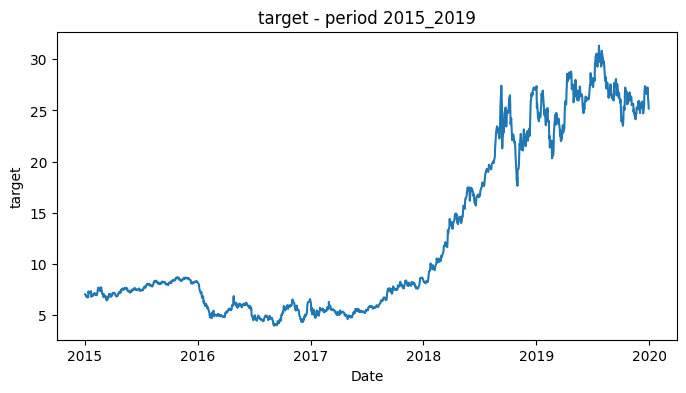

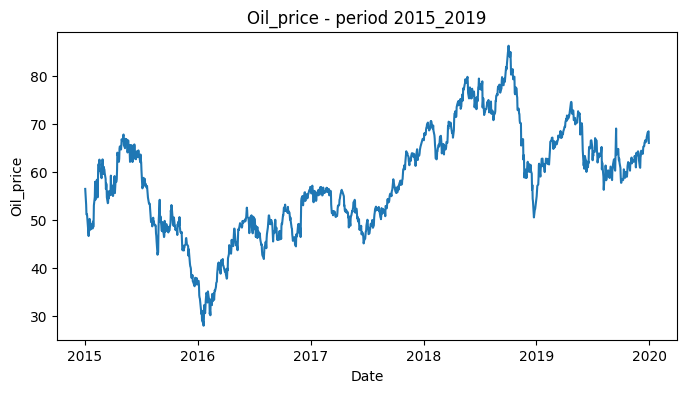

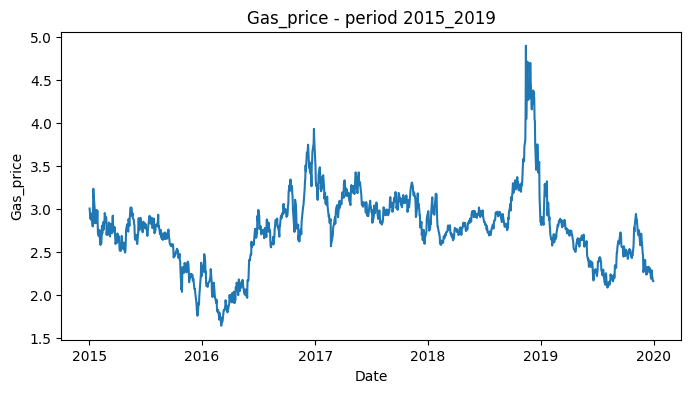

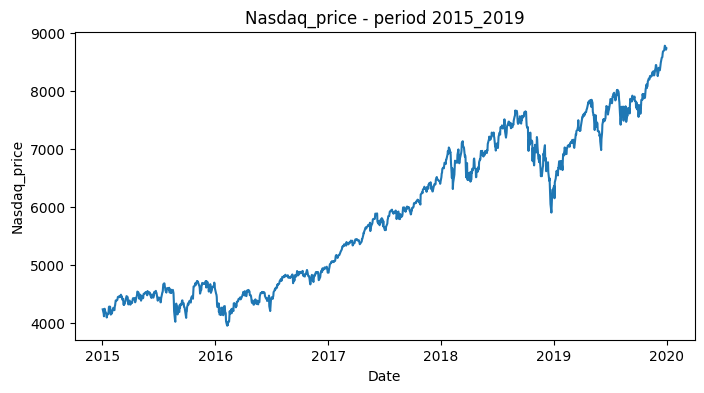

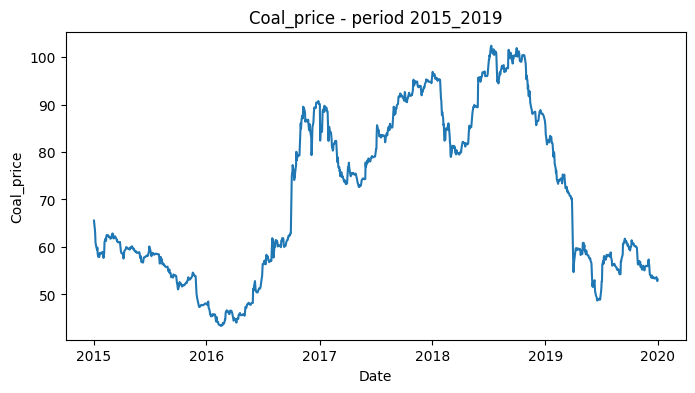

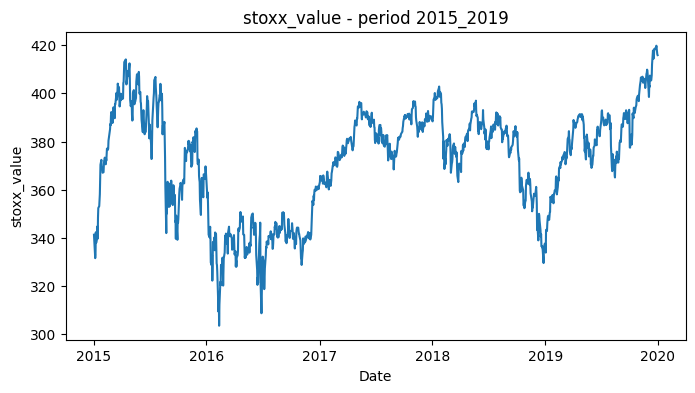

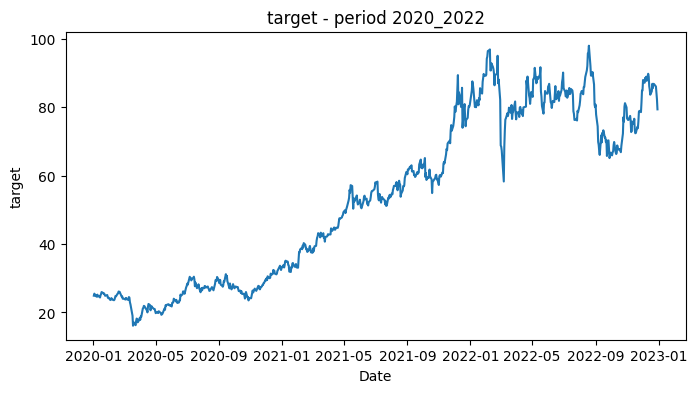

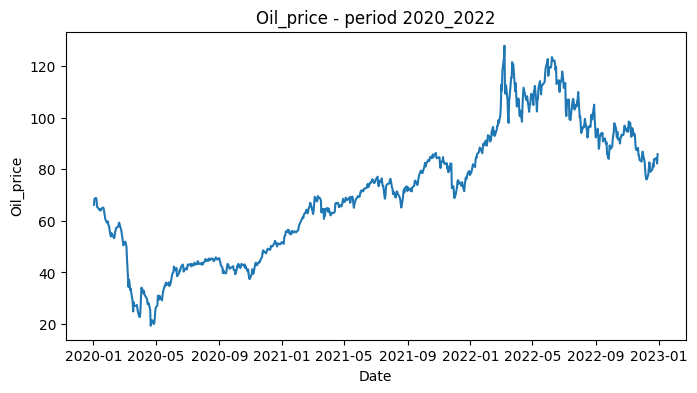

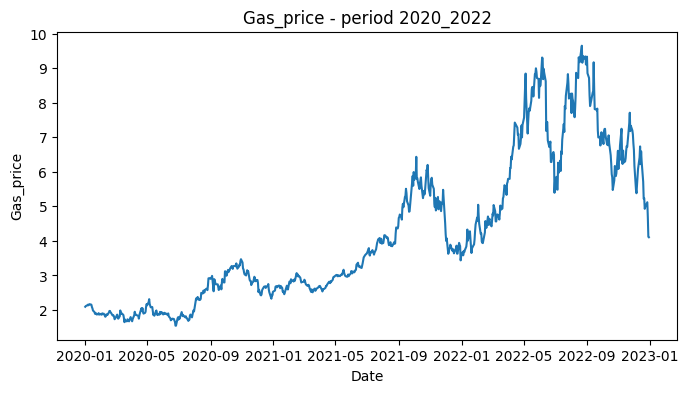

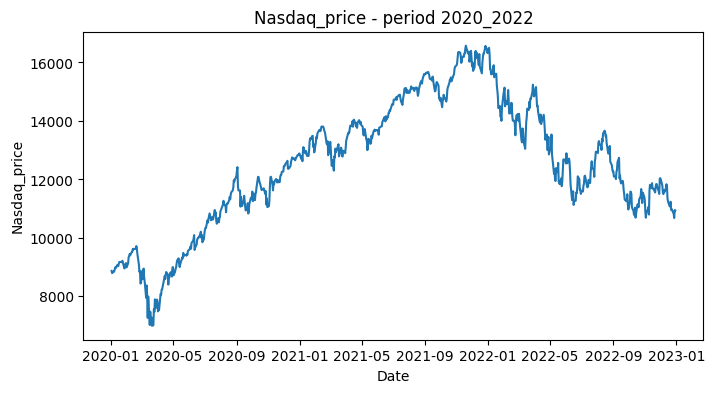

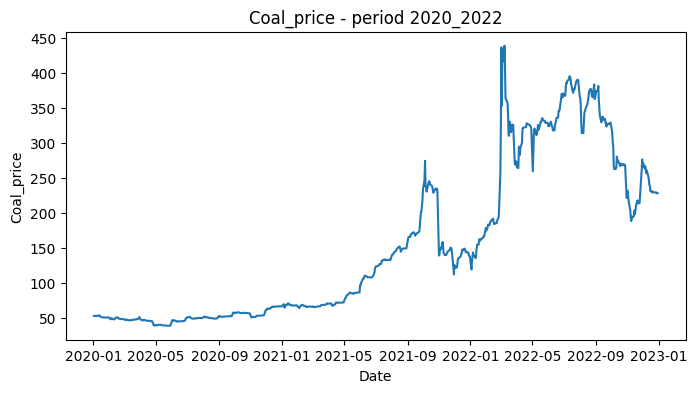

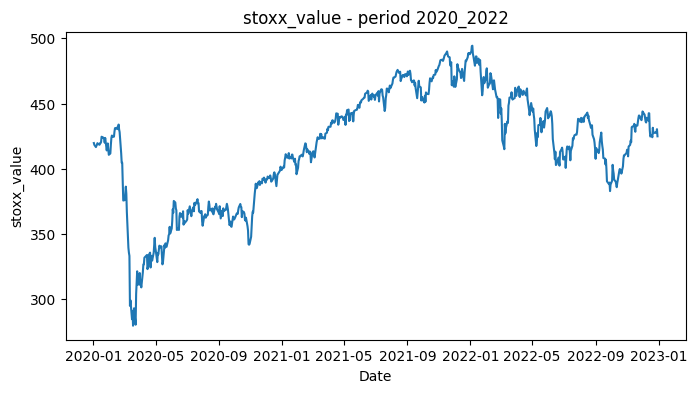

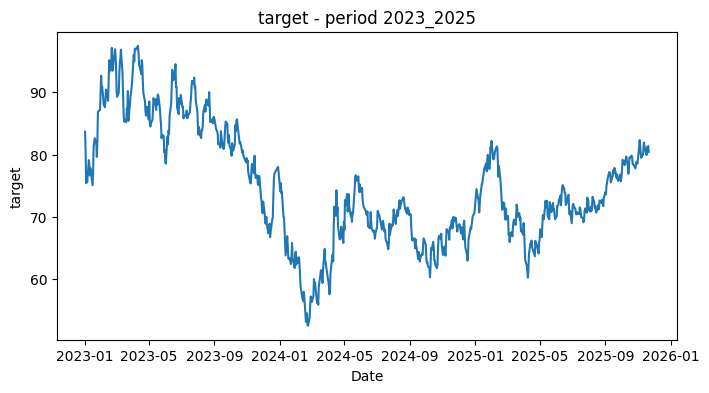

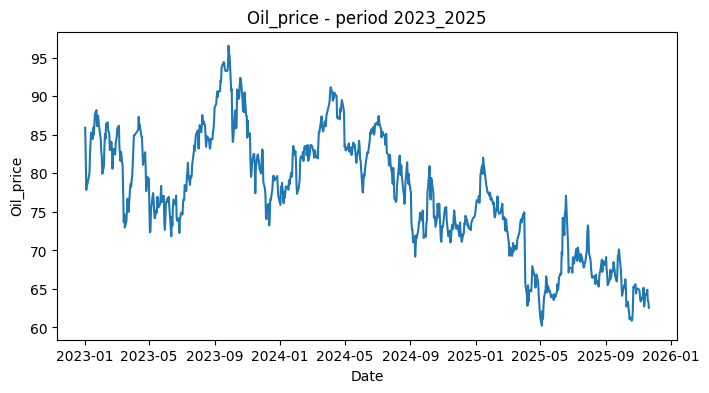

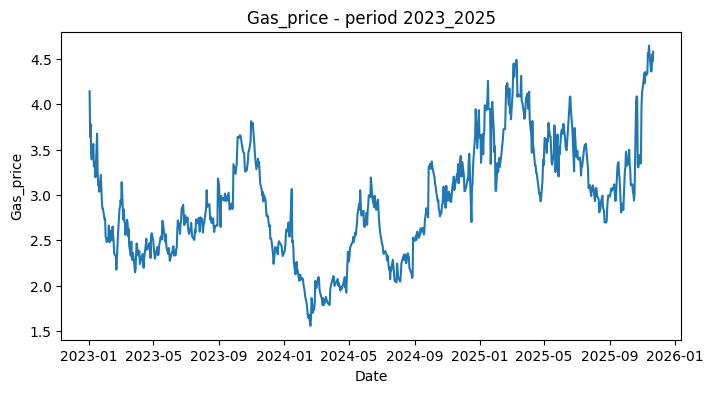

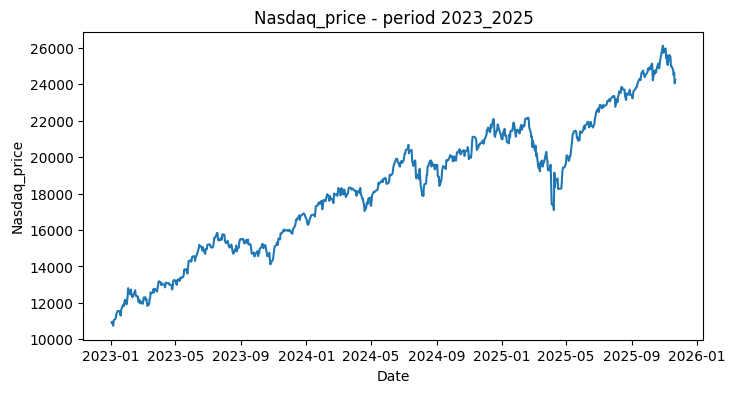

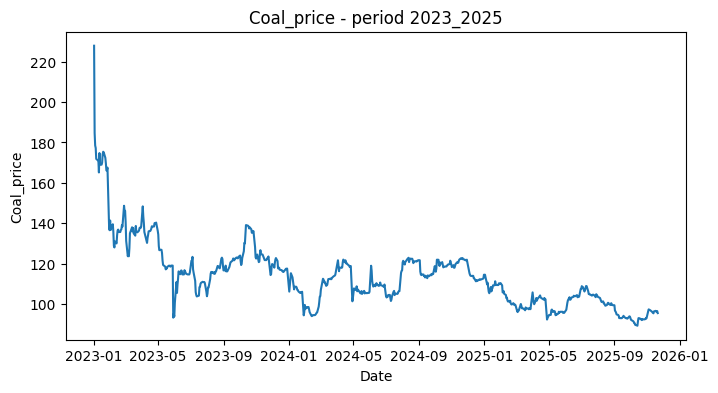

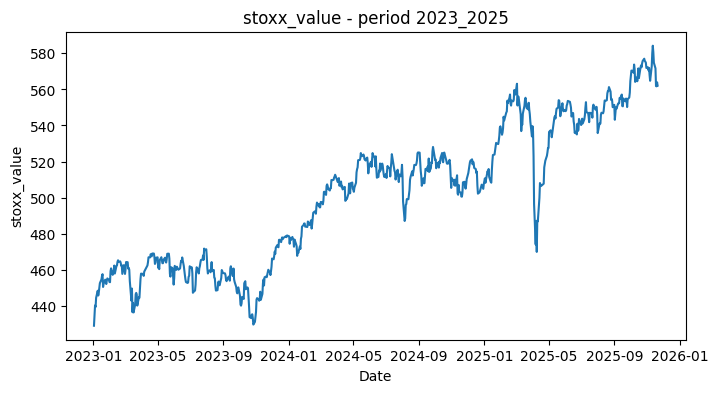

In [12]:
for period, df in data_periods.items():    
    for col in cols: 
        plt.figure(figsize = (8, 4))
        plt.plot(df['Date'], df[col])
        plt.title(f'{col} - period {period}')
        plt.xlabel('Date')
        plt.ylabel(f'{col}')
        plt.show()

### Logged time series

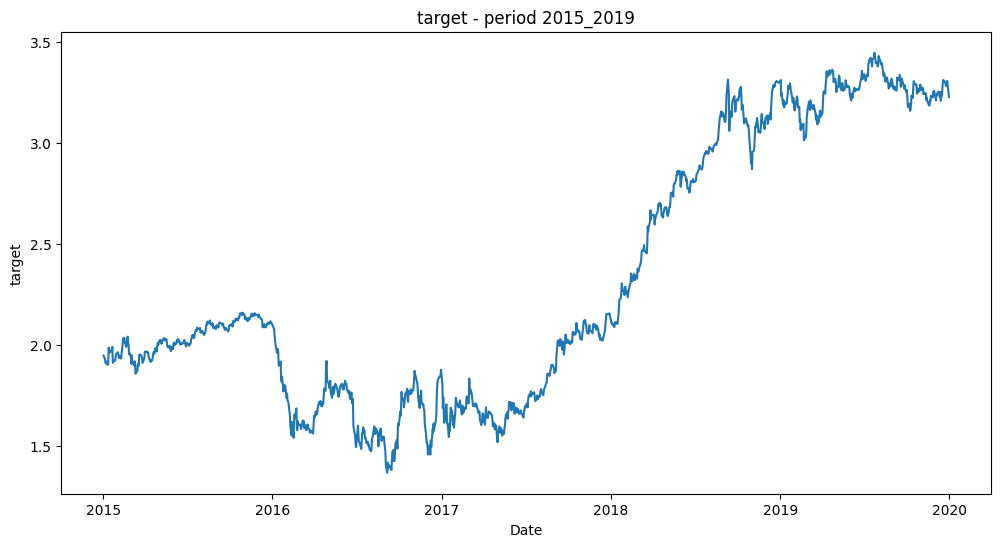

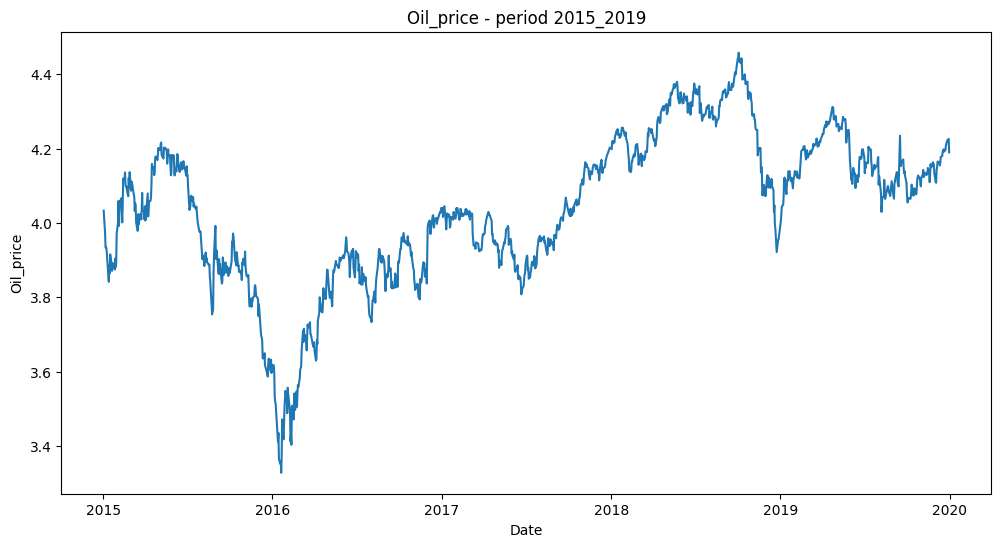

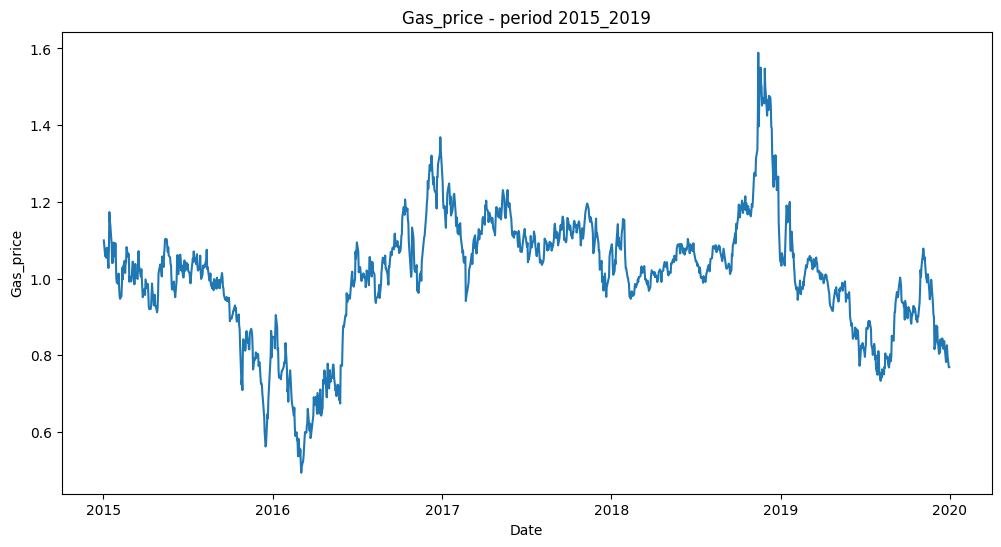

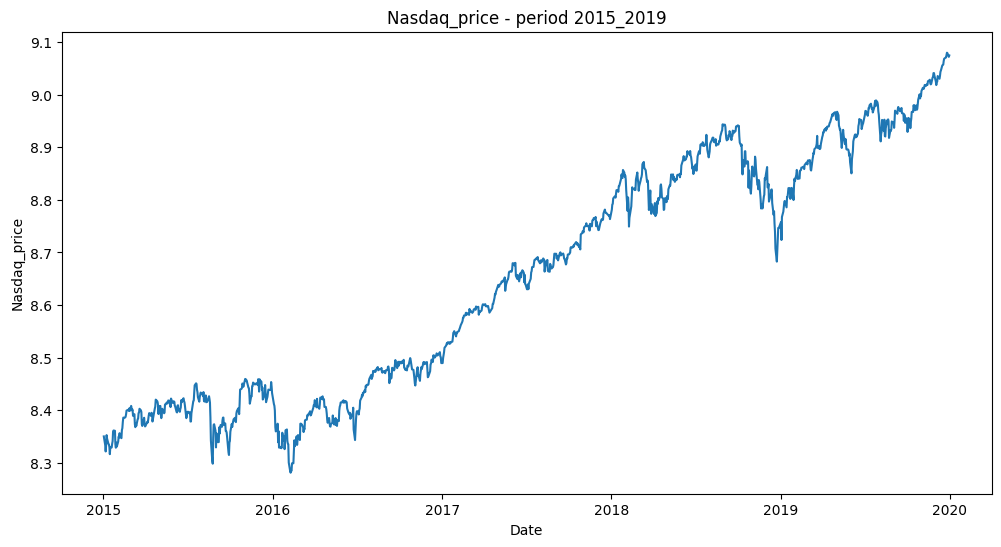

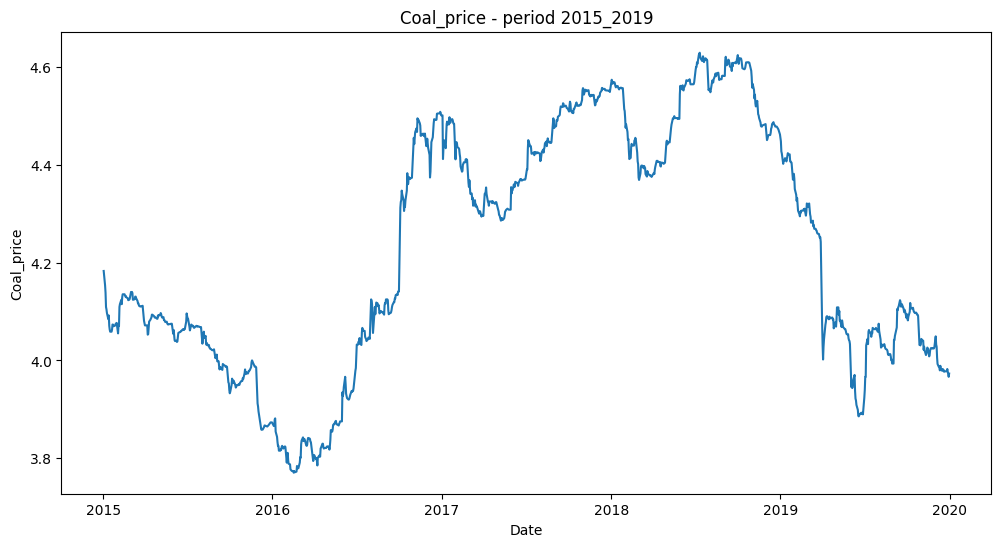

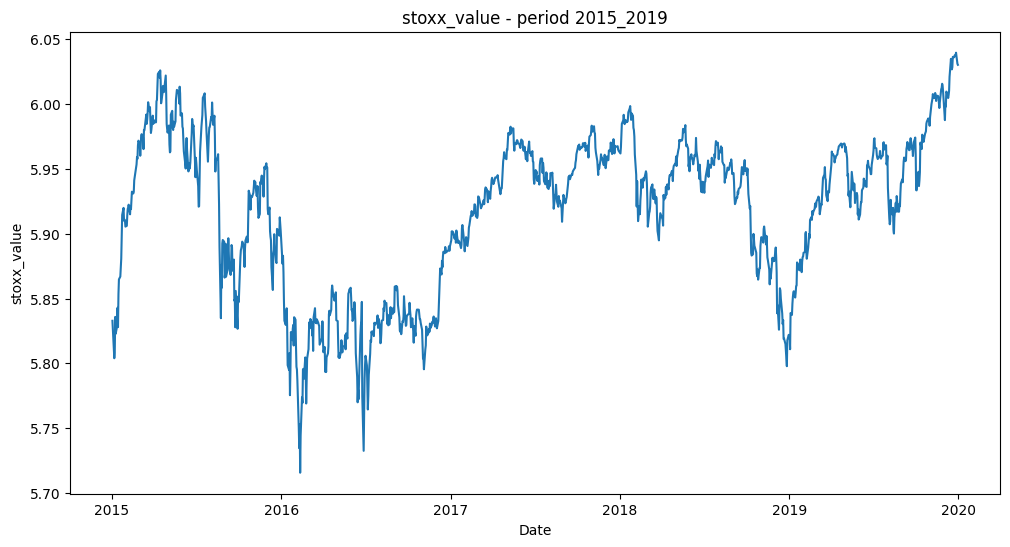

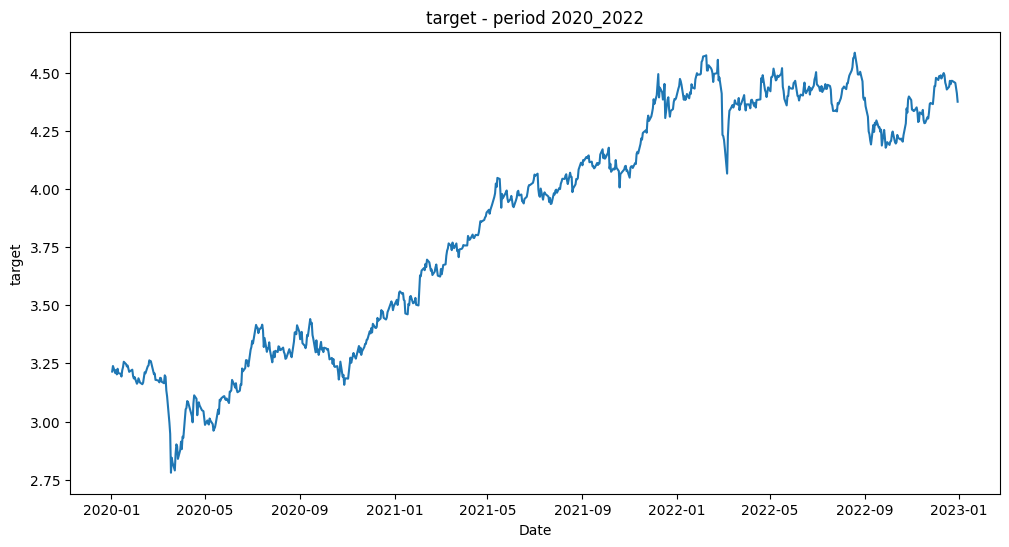

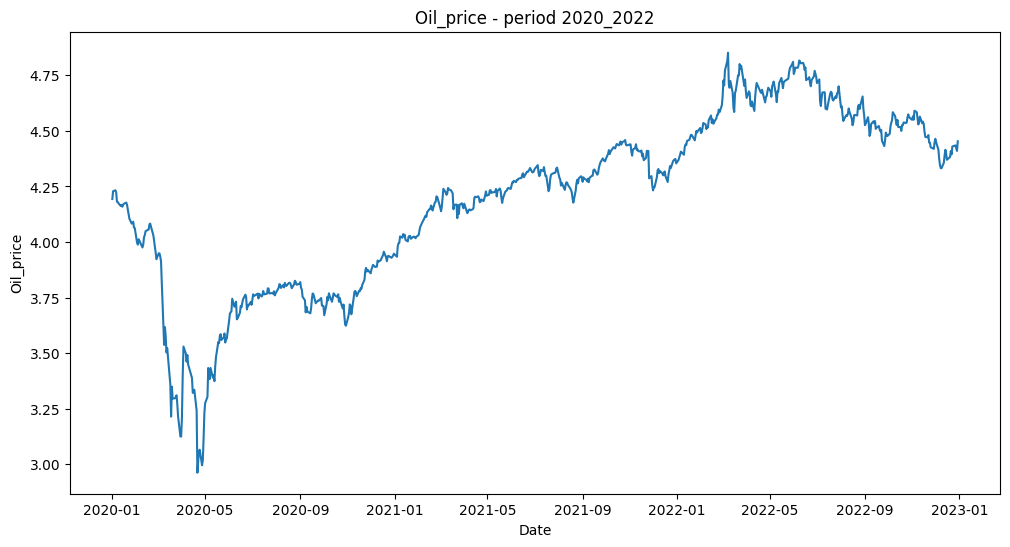

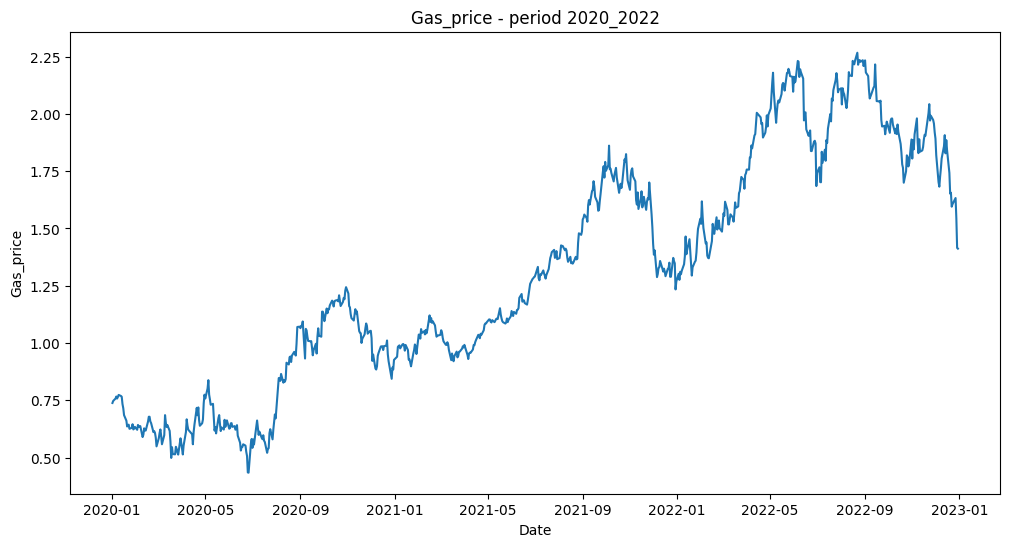

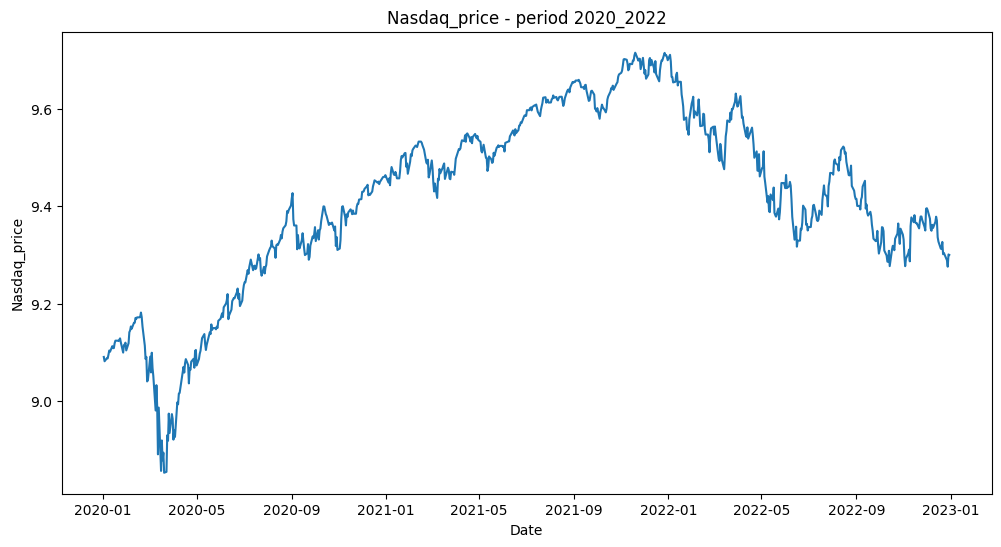

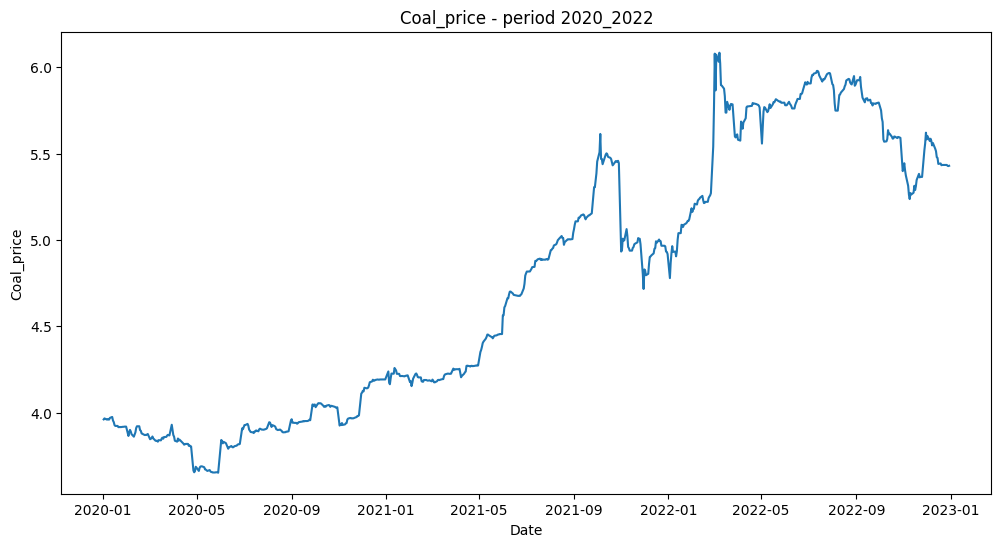

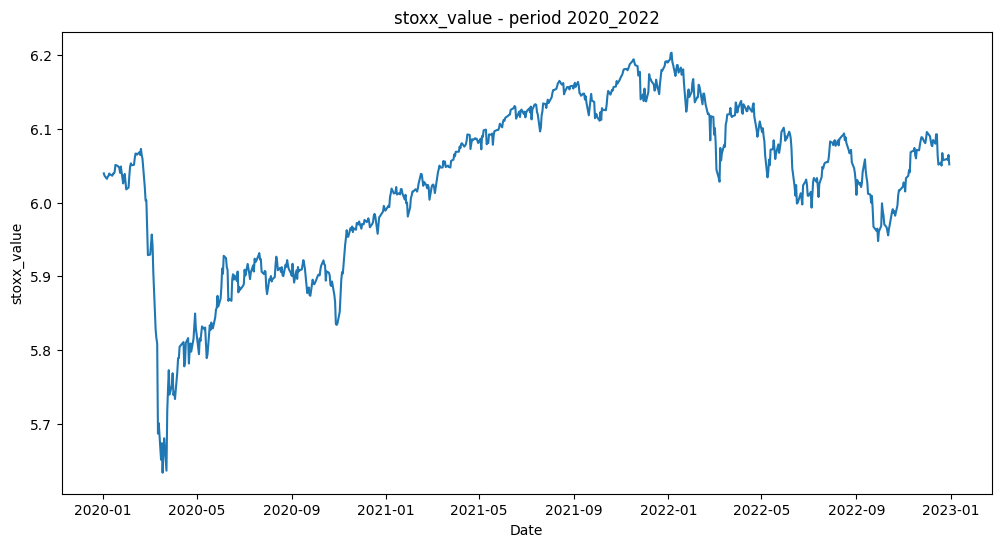

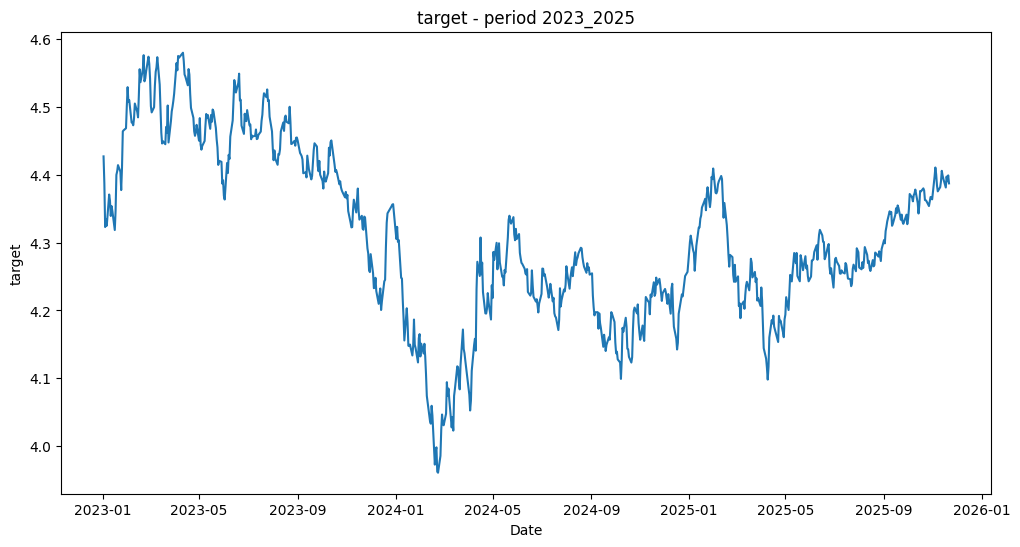

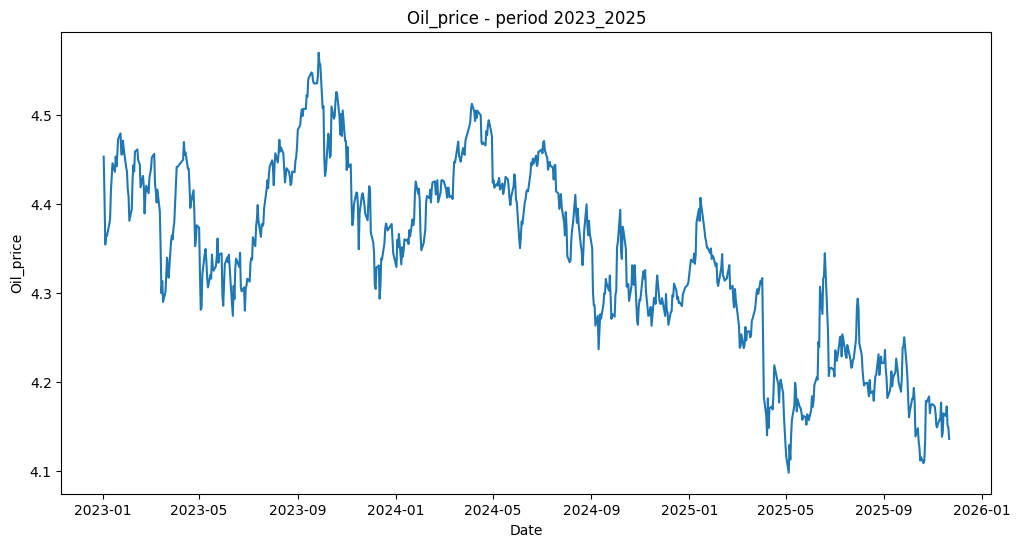

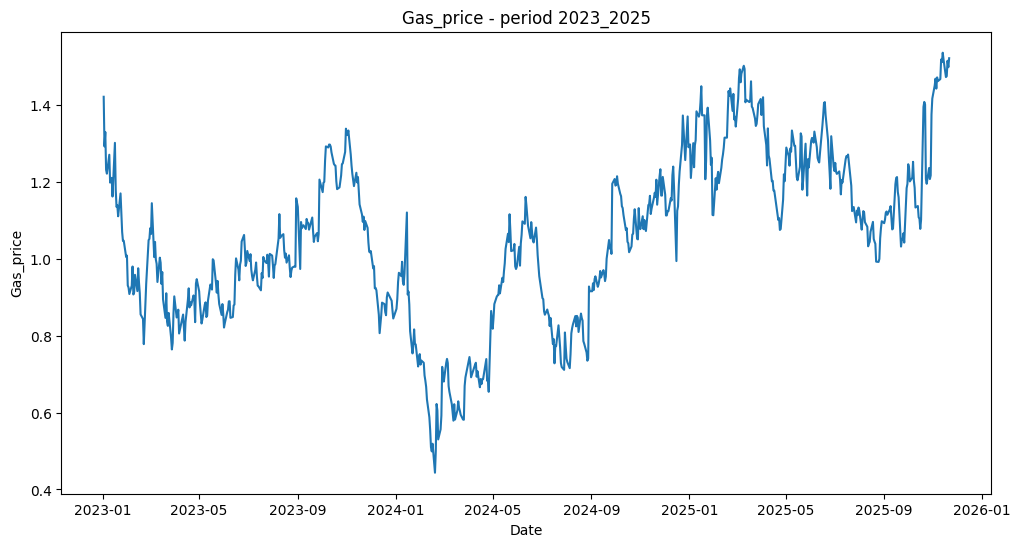

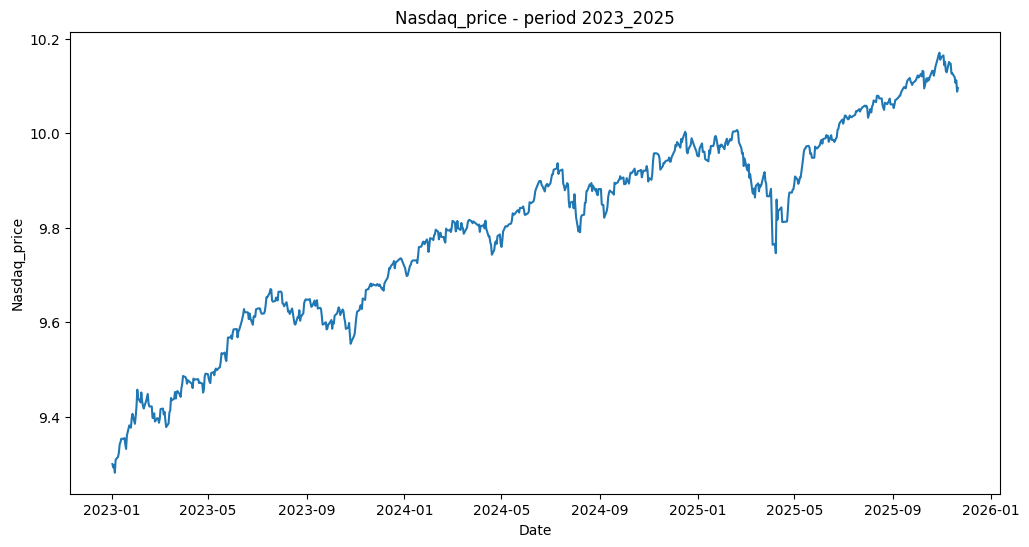

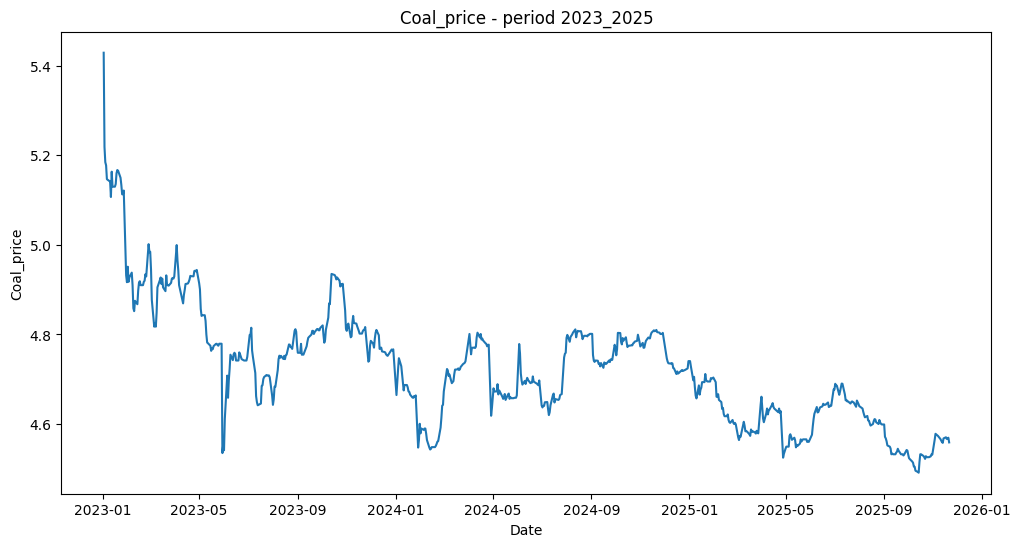

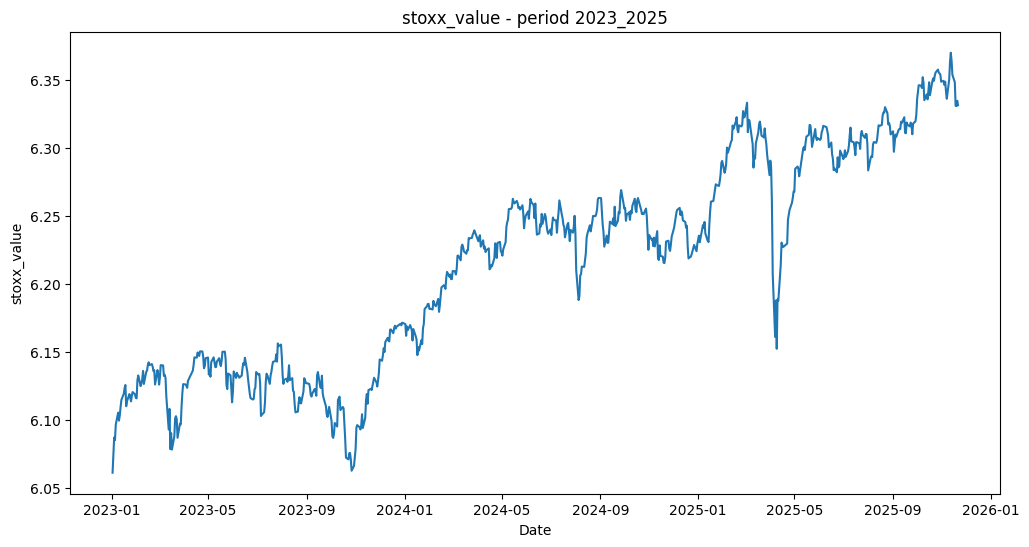

In [13]:
for period, dataset in data_periods.items():   
    df = dataset.copy() 
    df[cols] = np.log(df[cols])
    for col in cols: 
        plt.figure(figsize = (12, 6))
        plt.plot(df['Date'], df[col])
        plt.title(f'{col} - period {period}')
        plt.xlabel('Date')
        plt.ylabel(f'{col}')
        plt.show()

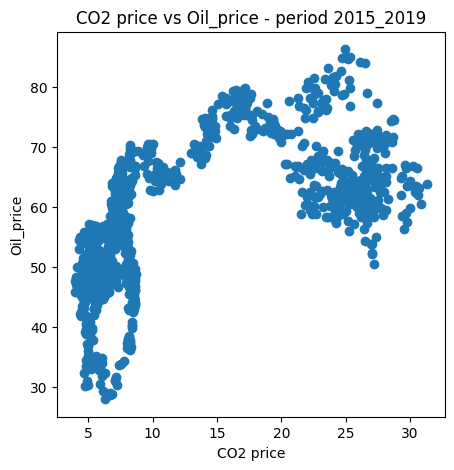

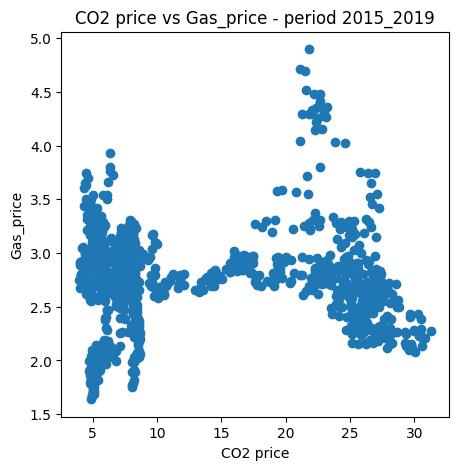

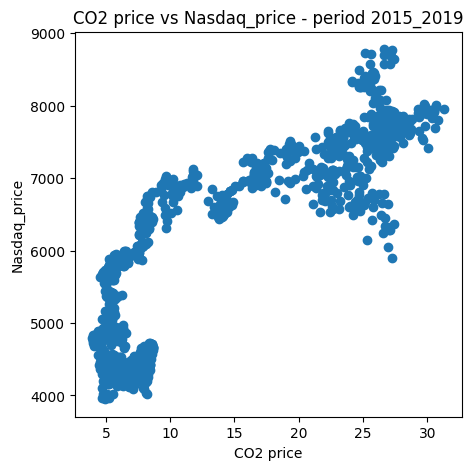

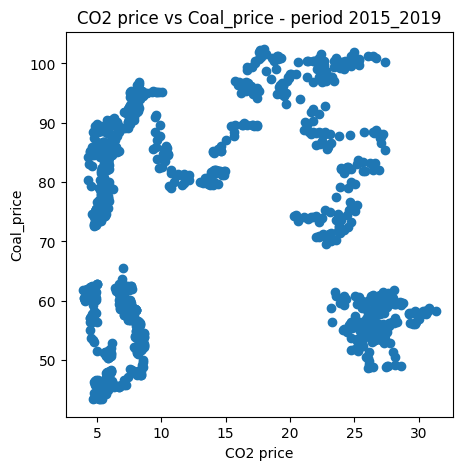

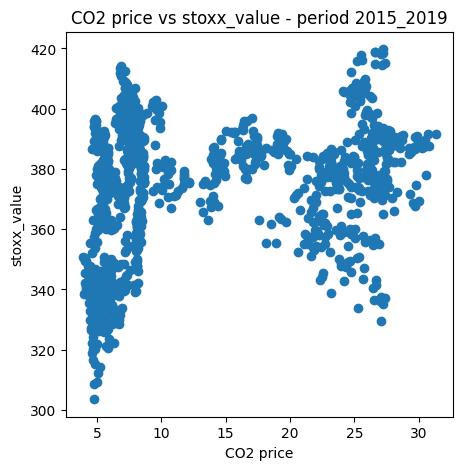

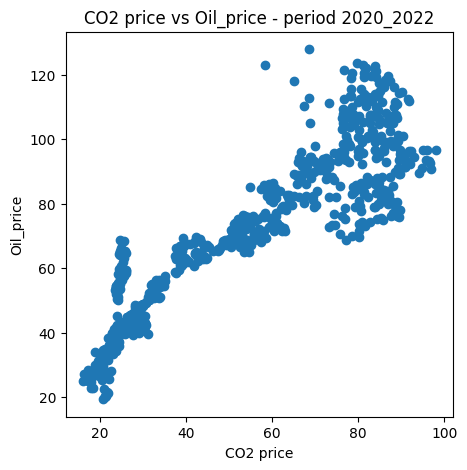

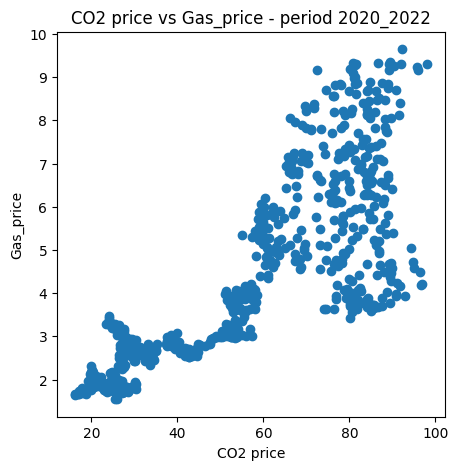

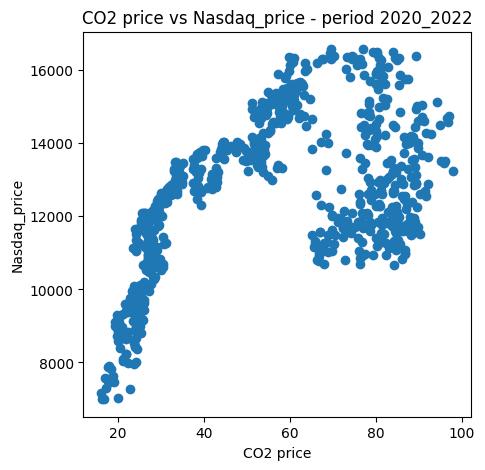

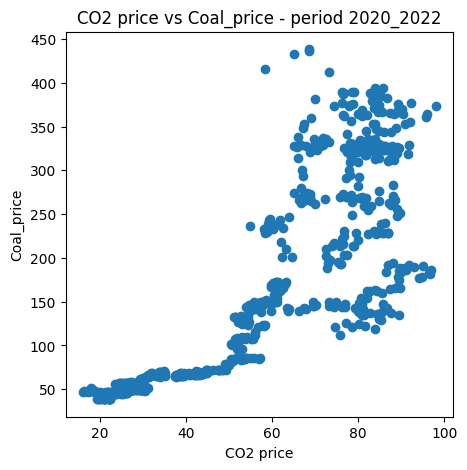

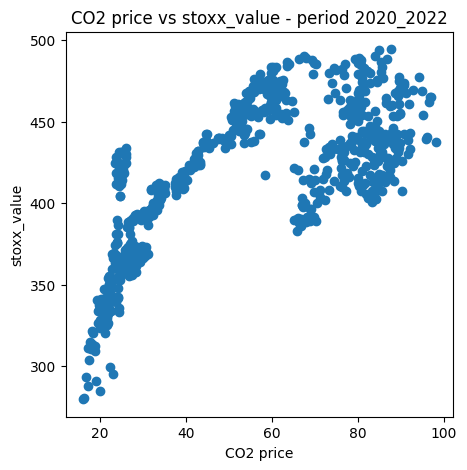

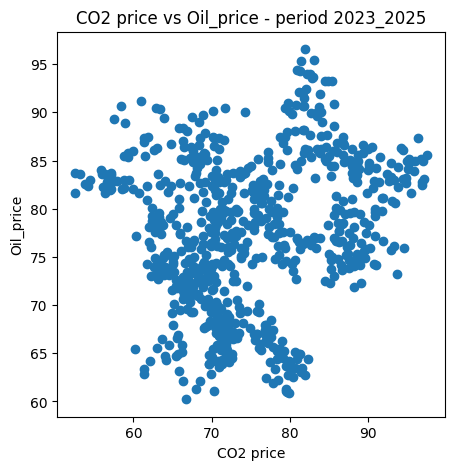

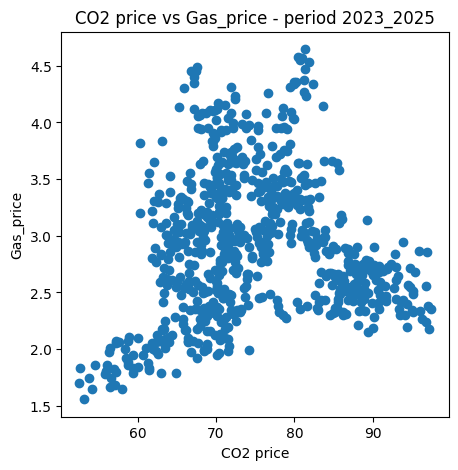

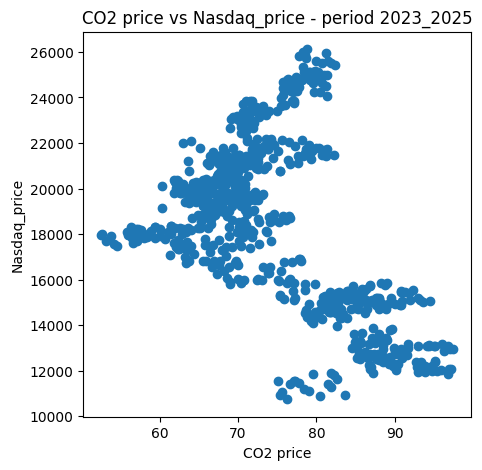

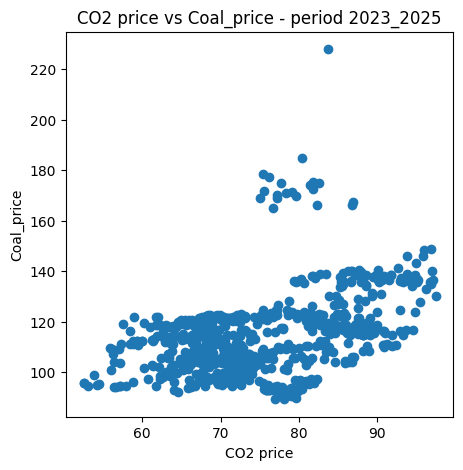

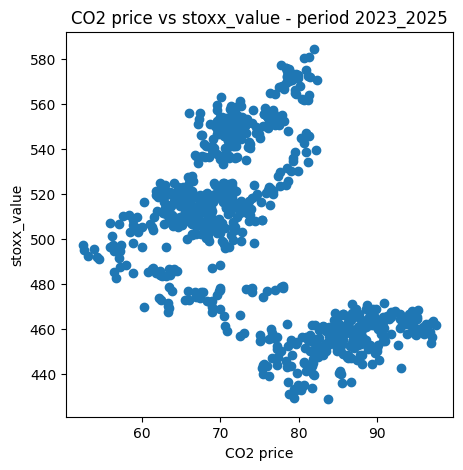

In [15]:
for period, df in data_periods.items():    
    for col in cols: 
        if col != 'target':
            plt.figure(figsize = (5, 5))
            plt.scatter(df['target'], df[col])
            plt.title(f'CO2 price vs {col} - period {period}')
            plt.xlabel('CO2 price')
            plt.ylabel(f'{col}')
            plt.show()

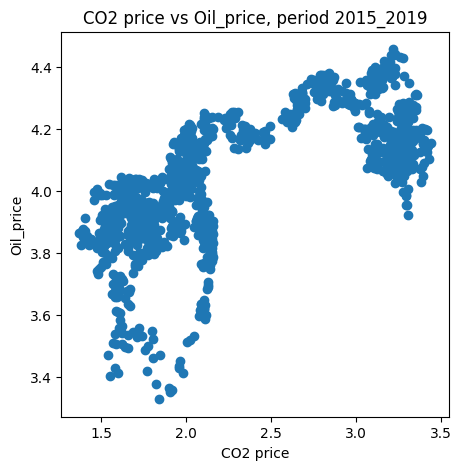

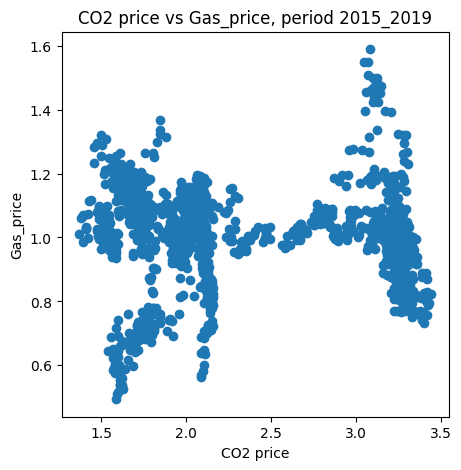

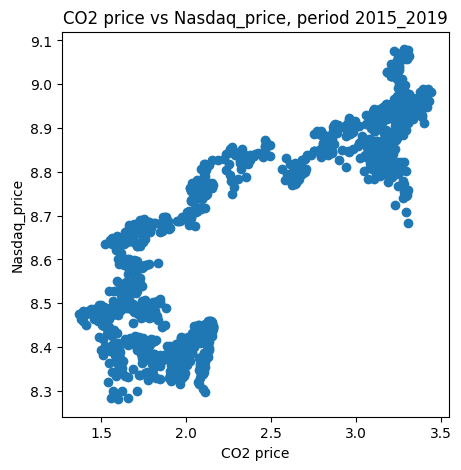

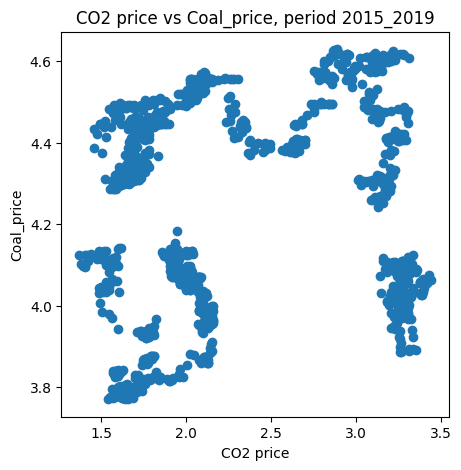

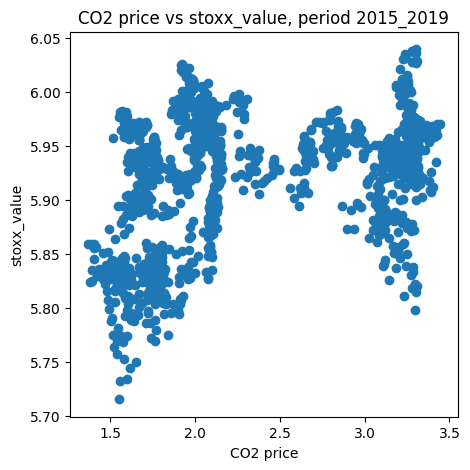

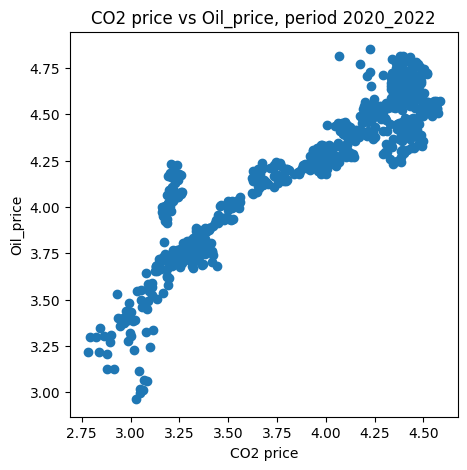

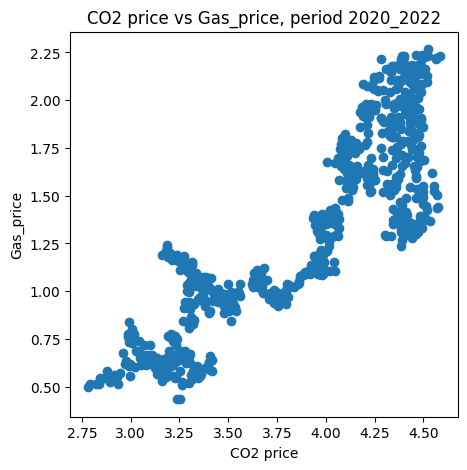

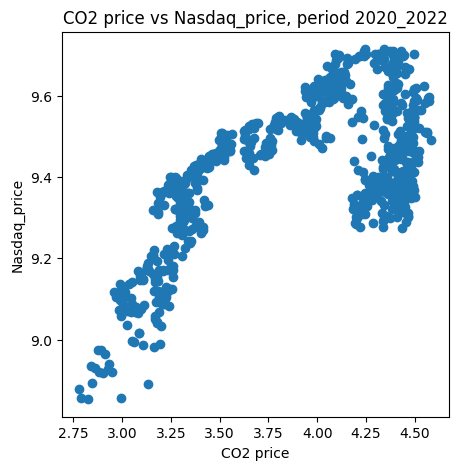

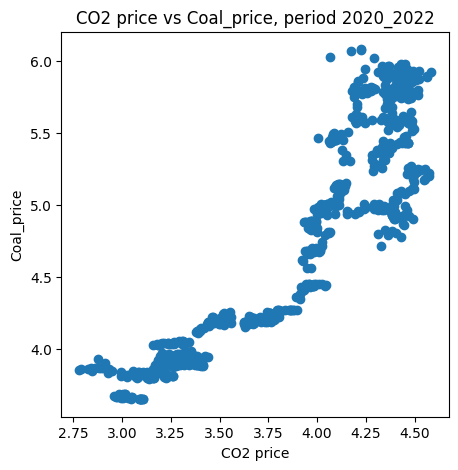

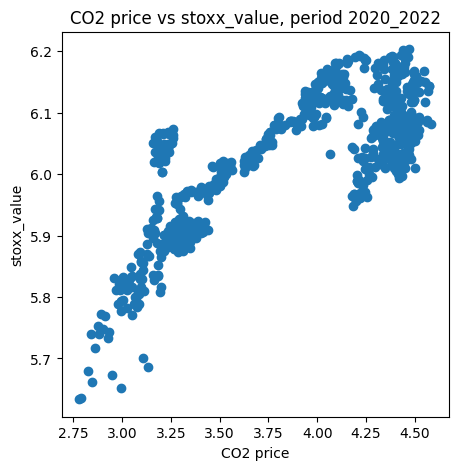

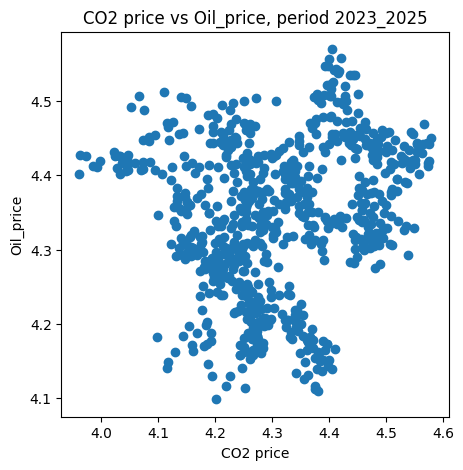

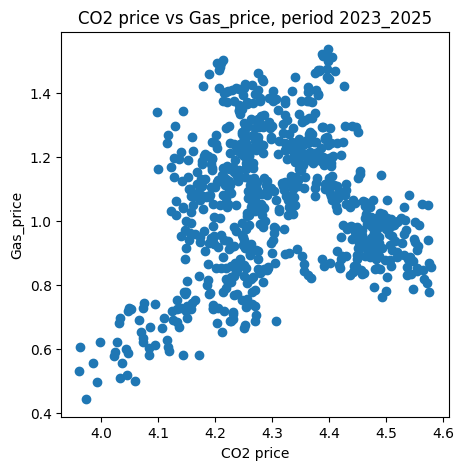

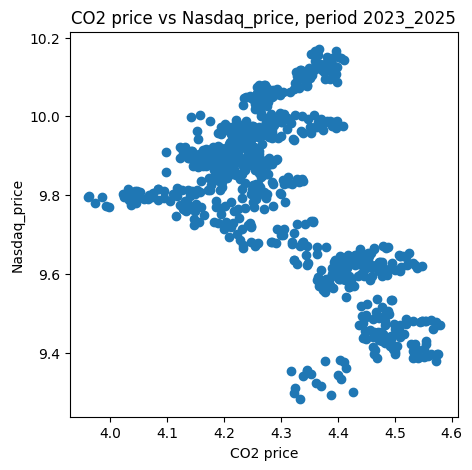

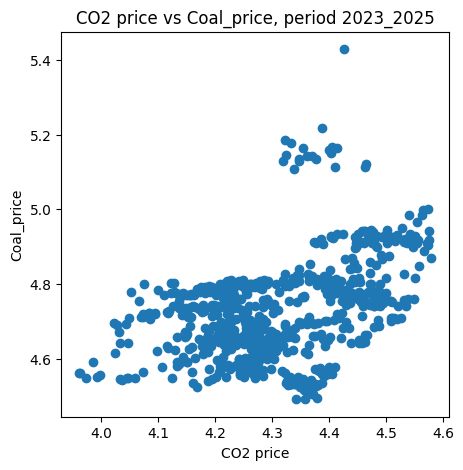

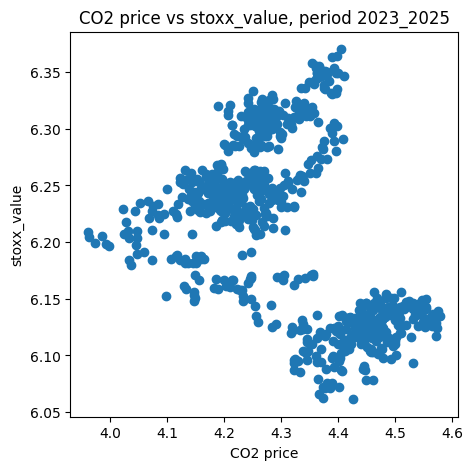

In [16]:
for period, dataset in data_periods.items():
    df = dataset.copy()
    df[cols] = np.log(df[cols])    
    for col in cols: 
        if col != 'target':
            plt.figure(figsize = (5, 5))
            plt.scatter(df['target'], df[col])
            plt.title(f'CO2 price vs {col}, period {period}')
            plt.xlabel('CO2 price')
            plt.ylabel(f'{col}')
            plt.show()

## Statistical tests

### ADF test

#### Raw time-series

In [ ]:
alpha = 0.01
stationary = []
for period, df in data_periods.items():    
    for col in cols: 
        adf_test = adfuller(df[col], result_object= True)
        p_value = adf_test[1]
        if p_value < alpha: # appending if stationary
            stationary.append(period + " " + col)

stationary
        


['2023_2025 Coal_price']

#### Diffs time series

In [ ]:
alpha = 0.01
not_stationary = []
for period, df in data_periods.items():    
    for col in cols: 
        adf_test = adfuller(df[col].diff().dropna(), result_object= True)
        p_value = adf_test[1]
        if p_value > alpha: # here appending if not stationary
            not_stationary.append(period + " " + col)

not_stationary
        


[]

#### Logged time series - levels

In [23]:
alpha = 0.01
stationary = []
for period, dataset in data_periods.items():  
    df = dataset.copy()
    df[cols] = np.log(df[cols])  
    for col in cols: 
        adf_test = adfuller(df[col], result_object= True)
        p_value = adf_test[1]
        if p_value < alpha: # appending if stationary
            stationary.append(period + " " + col)

stationary
        


[]

#### Logged time series - diffs

In [ ]:
alpha = 0.01
not_stationary = []
for period, df in data_periods.items():    
    df = dataset.copy()
    df[cols] = np.log(df[cols])  
    for col in cols: 
        adf_test = adfuller(df[col].diff().dropna(), result_object= True)
        p_value = adf_test[1]
        if p_value > alpha: # here appending if not stationary
            not_stationary.append(period + " " + col)

not_stationary
        


[]

### Cointegration tests

#### One variable - CO2 price

##### Raw time-series

In [ ]:
alpha_coint = 0.05

cointegrated_levels_raw = []

for period, df in data_periods.items():
    for col in cols: 
        if col != 'target': 
            coint_test = coint(df['target'], df[col], trend = 'c', return_results= True)
            p_value = coint_test[1]
            print(f'{col}, {period}, p_value: {p_value}')
            if p_value < alpha_coint: 
                cointegrated_levels_raw.append(period + " " + col)

print(cointegrated_levels_raw)



Oil_price, 2015_2019, p_value: 0.8687216063771128
Gas_price, 2015_2019, p_value: 0.6660215422988999
Nasdaq_price, 2015_2019, p_value: 0.9129047864242831
Coal_price, 2015_2019, p_value: 0.8088606622584678
stoxx_value, 2015_2019, p_value: 0.8859164910113383
Oil_price, 2020_2022, p_value: 0.09596789816208051
Gas_price, 2020_2022, p_value: 0.3743189134269292
Nasdaq_price, 2020_2022, p_value: 0.22932126801865138
Coal_price, 2020_2022, p_value: 0.2532551317767191
stoxx_value, 2020_2022, p_value: 0.19229879921205867
Oil_price, 2023_2025, p_value: 0.34685069361756804
Gas_price, 2023_2025, p_value: 0.11961764260203722
Nasdaq_price, 2023_2025, p_value: 0.6505760421007014
Coal_price, 2023_2025, p_value: 0.669261958836421
stoxx_value, 2023_2025, p_value: 0.6657126912375793
[]


##### Logged time series

In [38]:
alpha_coint = 0.05

cointegrated_levels_log = []

for period, dataset in data_periods.items():
    df = dataset.copy()
    df[cols] = np.log(df[cols])
    for col in cols: 
        if col != 'target': 
            coint_test = coint(df['target'], df[col], trend = 'ctt', return_results= True)
            p_value = coint_test[1]
            print(f'{col}, {period}, p_value: {p_value}')
            if p_value < alpha_coint: 
                cointegrated_levels_log.append(period + " " + col)

print(cointegrated_levels_log)



Oil_price, 2015_2019, p_value: 0.9596833689054108
Gas_price, 2015_2019, p_value: 0.9885837035967256
Nasdaq_price, 2015_2019, p_value: 0.9772730378027779
Coal_price, 2015_2019, p_value: 0.9801176690989137
stoxx_value, 2015_2019, p_value: 0.9907743017399531
Oil_price, 2020_2022, p_value: 0.15938173844425702
Gas_price, 2020_2022, p_value: 0.2735551626767037
Nasdaq_price, 2020_2022, p_value: 0.3890384679221373
Coal_price, 2020_2022, p_value: 0.12287810538243477
stoxx_value, 2020_2022, p_value: 0.06404385761556458
Oil_price, 2023_2025, p_value: 0.1344372663952108
Gas_price, 2023_2025, p_value: 0.02107255041382606
Nasdaq_price, 2023_2025, p_value: 0.15040846374559547
Coal_price, 2023_2025, p_value: 0.15414720922611747
stoxx_value, 2023_2025, p_value: 0.1254510081099945
['2023_2025 Gas_price']


#### Variables pairs - CO2 price

In [39]:

pairs = [list(pair) for pair in combinations(cols[1:], 2)]
print(pairs)


[['Oil_price', 'Gas_price'], ['Oil_price', 'Nasdaq_price'], ['Oil_price', 'Coal_price'], ['Oil_price', 'stoxx_value'], ['Gas_price', 'Nasdaq_price'], ['Gas_price', 'Coal_price'], ['Gas_price', 'stoxx_value'], ['Nasdaq_price', 'Coal_price'], ['Nasdaq_price', 'stoxx_value'], ['Coal_price', 'stoxx_value']]


##### Raw time-series

In [53]:
coint_pairs_raw = {}

alpha_coint = 0.05

for period, df in data_periods.items():
    for pair in pairs: 
        coint_test = coint(df['target'], df[pair], trend = 'ctt', return_results= True)
        p_value = coint_test[1]
        if p_value < alpha_coint: 
            coint_pairs_raw[period + ', ' + pair[0] + ' & ' + pair[1]] = p_value
            print(f'Cointegration does occur between CO2 price and {pair} in period {period}')
        else: 
            print(f'Cointegration does not occur between CO2 price and {pair} in period {period}')
        print(f'p_value: {p_value}')

print(coint_pairs_raw)

Cointegration does not occur between CO2 price and ['Oil_price', 'Gas_price'] in period 2015_2019
p_value: 0.989600505976783
Cointegration does not occur between CO2 price and ['Oil_price', 'Nasdaq_price'] in period 2015_2019
p_value: 0.719812221588698
Cointegration does not occur between CO2 price and ['Oil_price', 'Coal_price'] in period 2015_2019
p_value: 0.9828779046674405
Cointegration does not occur between CO2 price and ['Oil_price', 'stoxx_value'] in period 2015_2019
p_value: 0.1652494989552622
Cointegration does not occur between CO2 price and ['Gas_price', 'Nasdaq_price'] in period 2015_2019
p_value: 0.9940100587819375
Cointegration does not occur between CO2 price and ['Gas_price', 'Coal_price'] in period 2015_2019
p_value: 0.9942863269393069
Cointegration does not occur between CO2 price and ['Gas_price', 'stoxx_value'] in period 2015_2019
p_value: 0.9618244170922773
Cointegration does not occur between CO2 price and ['Nasdaq_price', 'Coal_price'] in period 2015_2019
p_valu

In [50]:
coint_pairs_log = {}

alpha_coint = 0.05

for period, dataset in data_periods.items():
    df = dataset.copy()
    df[cols] = np.log(df[cols])
    for pair in pairs: 
        coint_test = coint(df['target'], df[pair], trend = 'ctt', return_results= True)
        p_value = coint_test[1]
        if p_value < alpha_coint: 
            coint_pairs_log[period + ', ' + pair[0] + ' & ' + pair[1]] = p_value
            print(f'Cointegration does occur between CO2 price and {pair} in period {period}')
        else: 
            print(f'Cointegration does not occur between CO2 price and {pair} in period {period}')
        print(f'p_value: {p_value}')

print(coint_pairs_log)

Cointegration does not occur between CO2 price and ['Oil_price', 'Gas_price'] in period 2015_2019
p_value: 0.9776950130127191
Cointegration does not occur between CO2 price and ['Oil_price', 'Nasdaq_price'] in period 2015_2019
p_value: 0.9842741888568879
Cointegration does not occur between CO2 price and ['Oil_price', 'Coal_price'] in period 2015_2019
p_value: 0.982283733245406
Cointegration does not occur between CO2 price and ['Oil_price', 'stoxx_value'] in period 2015_2019
p_value: 0.7676582360442947
Cointegration does not occur between CO2 price and ['Gas_price', 'Nasdaq_price'] in period 2015_2019
p_value: 0.9912214281007354
Cointegration does not occur between CO2 price and ['Gas_price', 'Coal_price'] in period 2015_2019
p_value: 0.98036310310492
Cointegration does not occur between CO2 price and ['Gas_price', 'stoxx_value'] in period 2015_2019
p_value: 0.9952038345378188
Cointegration does not occur between CO2 price and ['Nasdaq_price', 'Coal_price'] in period 2015_2019
p_value